In [1]:
import pandas as pd
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:

# Download NLTK resources (run once)
nltk.download('stopwords')
nltk.download('wordnet')

# Step 1: Load the CSV file
# Replace 'your_file.csv' with the path to your CSV file
df = pd.read_csv('/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/leo_search_results.csv')

# Ensure the 'Summary' column exists
if 'Summary' not in df.columns:
    raise ValueError("The CSV file must contain a 'Summary' column.")

# Step 2: Preprocess the text
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    # Handle non-string inputs (e.g., NaN or numbers)
    if not isinstance(text, str):
        return ""
    # Convert to lowercase
    text = text.lower()
    # Remove punctuation and special characters
    text = re.sub(r'[^\w\s]', '', text)
    # Tokenize and remove stopwords
    tokens = [word for word in text.split() if word not in stop_words]
    # Lemmatize
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    # Join tokens back into a string
    return ' '.join(tokens)

# Apply preprocessing to the 'Summary' column
df['Processed_Summary'] = df['Summary'].apply(preprocess_text)

# Step 3: Convert text to vectors
# Use TF-IDF to transform text into numerical features
vectorizer = TfidfVectorizer(max_features=1000, ngram_range=(1, 2))
X = vectorizer.fit_transform(df['Processed_Summary'])

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/emine2/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/emine2/nltk_data...


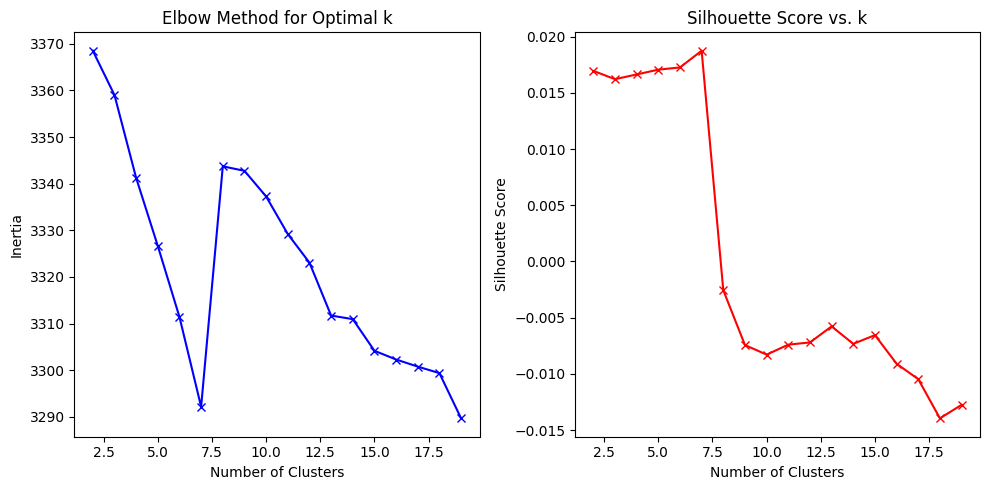

In [3]:


# Step 4: Determine the optimal number of clusters using the elbow method
inertia = []
silhouette_scores = []
K = range(2, 20)  # Test 2 to 10 clusters

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)
    if k > 1:  # Silhouette score requires at least 2 clusters
        score = silhouette_score(X, kmeans.labels_)
        silhouette_scores.append(score)
    else:
        silhouette_scores.append(0)  # Placeholder for k=1

# Plot the elbow curve
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(K, inertia, 'bx-')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')

# Plot the silhouette scores
plt.subplot(1, 2, 2)
plt.plot(K, silhouette_scores, 'rx-')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs. k')
plt.tight_layout()
plt.show()



Cluster 0:
  1. Gardening columnist Jeff Lowenfels explains how trees are built to survive extreme high winds. 
  2. Kenai has extended agreements with state authorities to continue its spruce tree mitigation efforts, addressing trees affected by spruce beetles.
  3. A severe fall storm in 2024 exposed coastal permafrost in Kotzebue, revealing ice layers previously covered by clay or plants and raising concerns about increased melting and environmental contamination.
  4. A new plant species is establishing itself in the area and impacting native beach greens. 
  5. A close look at this fallen spruce tree raises questions underlying causes and tree health. 

Cluster 1:
  1. Dawson City's annual ice bridge on the Yukon River was closed early due to warm temperatures and rain creating unsafe conditions for travelers.
  2. During Iditarod 53, mushers and their sled dogs battled high winds that whipped up a sandstorm near the Tanana River, forcing teams to pause and regroup. The unexpecte

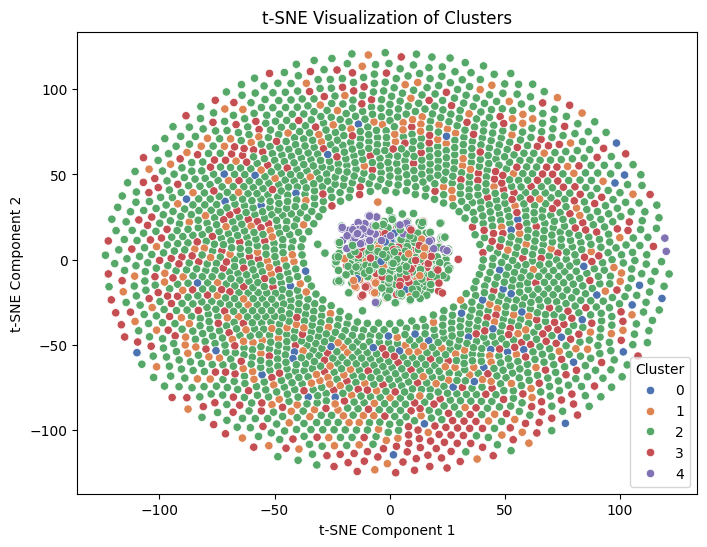

In [4]:

# Step 5: Choose the number of clusters
# Based on the elbow plot and silhouette scores, select an optimal k
optimal_k = 5  # Adjust this based on the plots (e.g., where the elbow bends or silhouette score peaks)

# Step 6: Perform clustering with the chosen k
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
df['Cluster'] = kmeans.fit_predict(X)

# Step 7: Analyze the clusters
# Display a few summaries from each cluster to understand the categories
for cluster in range(optimal_k):
    print(f"\nCluster {cluster}:")
    cluster_samples = df[df['Cluster'] == cluster]['Summary'].head(5)
    for i, sample in enumerate(cluster_samples, 1):
        print(f"  {i}. {sample}")

# Optional: Save the results to a new CSV
df.to_csv('clustered_summaries.csv', index=False)

# Step 8: Visualize the clusters (optional, using t-SNE for 2D visualization)
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X.toarray())

# Create a scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=df['Cluster'], palette='deep')
plt.title('t-SNE Visualization of Clusters')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.show()